In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(os.path.join("..", "hil_bench")))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import analysis as A, params as P, pr_design as D
claims = []
def claim(cid, text, number, source):
    claims.append({"ID": cid, "Claim": text, "Number": number, "Source": source})
NBID = "01"

# 01 · The emitter

**Question:** what exactly was built?

The emitter is one three-phase PV inverter: a DC source feeding a switching bridge, an LCL filter,
then a grid whose strength can be switched in steps. Its controller is told how much current to inject
at each harmonic order.

In [2]:
r = pd.DataFrame([
    ["Rated power", "100 kVA"], ["Grid voltage", "400 V line-line, 50 Hz"],
    ["Rated current (peak, per phase)", "%.1f A" % P.I_PK], ["DC voltage", "750 V (panel range 650-1000 V)"],
    ["Switching frequency", "%.0f kHz (controller runs once per switching period, %.0f µs)" % (P.F_SW / 1e3, P.TS * 1e6)],
    ["Filter, inverter side L1", "%.3f mH (0.10 pu)" % (P.L1 * 1e3)], ["Filter, grid side L2", "%.3f mH (0.03 pu)" % (P.L2 * 1e3)],
    ["Filter capacitor C", "%.1f µF (0.05 pu), damping resistor %.3f Ω" % (P.C * 1e6, P.RD)],
    ["Filter resonance on a stiff grid", "%.0f Hz" % P.F_RES]], columns=["Item", "Value"])
display(Markdown(A.md_table(r)))
claim("C1.1", "LCL filter resonance on a stiff grid", "%.0f Hz" % P.F_RES, "hil_bench/params.py")

| Item | Value |
|---|---|
| Rated power | 100 kVA |
| Grid voltage | 400 V line-line, 50 Hz |
| Rated current (peak, per phase) | 204.1 A |
| DC voltage | 750 V (panel range 650-1000 V) |
| Switching frequency | 10 kHz (controller runs once per switching period, 100 µs) |
| Filter, inverter side L1 | 0.509 mH (0.10 pu) |
| Filter, grid side L2 | 0.153 mH (0.03 pu) |
| Filter capacitor C | 99.5 µF (0.05 pu), damping resistor 0.362 Ω |
| Filter resonance on a stiff grid | 1472 Hz |

## What it is asked to inject

The request at each order is a fraction of the IEEE 1547-2018 current limit for that order
(IEEE Std 1547-2018, Table 26). In the panel you set a slider per order (0-1) and one master scale (0-1).
Most results here use **everything at its limit** (master 1) as a stress test.

TRD at full request: 6.82 %;  master for TRD = 5 %: 0.733


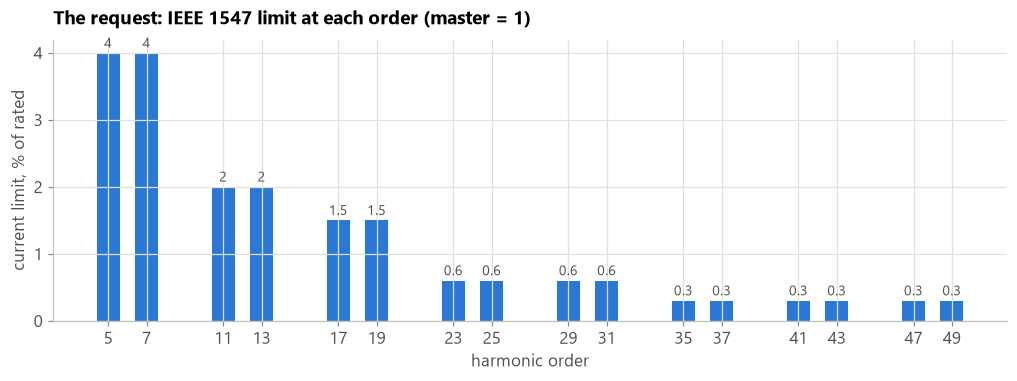

In [3]:
h = np.array(P.ORDERS); lim = np.array(P.PCT)
trd = np.sqrt((lim ** 2).sum())
fig, ax = A.panels(1, h=3.6)
ax[0].bar(h, lim, width=1.2, color=A.USED)
for hh, v in zip(h, lim):
    ax[0].text(hh, v + 0.08, "%g" % v, ha="center", fontsize=9, color=A.INK2)
ax[0].set_ylabel("current limit, % of rated")
ax[0].set_title("The request: IEEE 1547 limit at each order (master = 1)")
A.orders_axis(ax[0])
A.save(fig, "01_request", pd.DataFrame({"order": h, "limit_pct_of_rated": lim}))
claim("C1.2", "All 16 orders at their IEEE 1547 limit add up to a total distortion (TRD) of",
      "%.2f %% (IEEE 1547 allows 5 %%)" % trd, "IEEE Std 1547-2018 Table 26; computed here")
claim("C1.3", "Largest uniform master scale that keeps TRD at 5 %", "%.3f" % (5 / trd), "computed here")
print("TRD at full request: %.2f %%;  master for TRD = 5 %%: %.3f" % (trd, 5 / trd))

**Reading.** The low orders (5th, 7th) are allowed 4 % of rated current, the high orders 0.3 %.
Note: if every order sits at its own limit, the **total** is 6.82 %, above the 5 % total that IEEE 1547
also requires. So "everything at the limit" is a worst case, not a compliant inverter. A master of 0.733
meets both rules.

## The grid

The grid behind the PCC is a chain of R-L sections switched by contactors. Grid strength is given as
SCR (short-circuit power / inverter rating): **stiff** (no impedance), **SCR 20**, **SCR 10** and
**SCR 5** (weak). The X/R ratio is **assumed** to be 3.

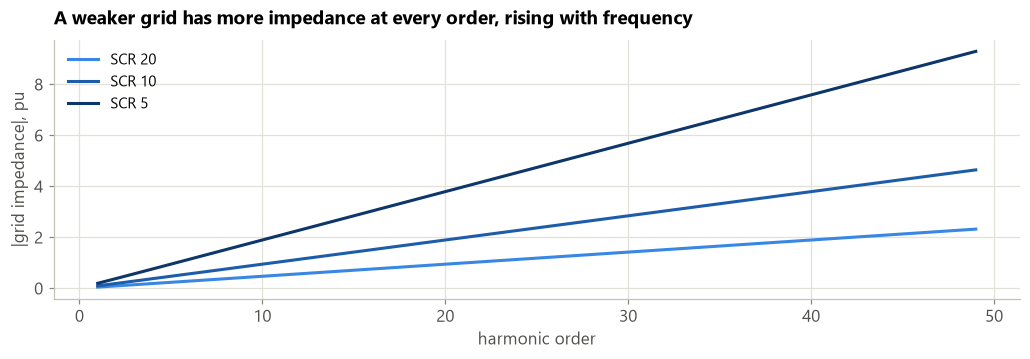

In [4]:
hh = np.arange(1, 50)
fig, ax = A.panels(1, h=3.4)
for g in A.GRIDS[1:]:
    ax[0].plot(hh, A.grid_z_pu(g, hh), color=A.GRID_COLOR[g], label=g)
ax[0].set_xlabel("harmonic order"); ax[0].set_ylabel("|grid impedance|, pu")
ax[0].set_title("A weaker grid has more impedance at every order, rising with frequency")
ax[0].legend()
A.save(fig, "01_grid_impedance", pd.DataFrame({"order": hh, **{g: A.grid_z_pu(g, hh) for g in A.GRIDS[1:]}}))

**Reading.** The grid is an inductance (plus some resistance), so its impedance grows in proportion
to the harmonic order. The same harmonic current makes 4 times more voltage on SCR 5 than on SCR 20.

## The filter on each grid

The LCL filter has a resonance. The grid inductance adds to the grid-side inductor, so the resonance
moves **down** as the grid gets weaker, right into the harmonic orders the emitter injects.

| grid | resonance_Hz | resonance_order |
|---|---|---|
| stiff | 1472 | 29.44 |
| SCR 20 | 1070 | 21.41 |
| SCR 10 | 948.9 | 18.98 |
| SCR 5 | 853 | 17.06 |

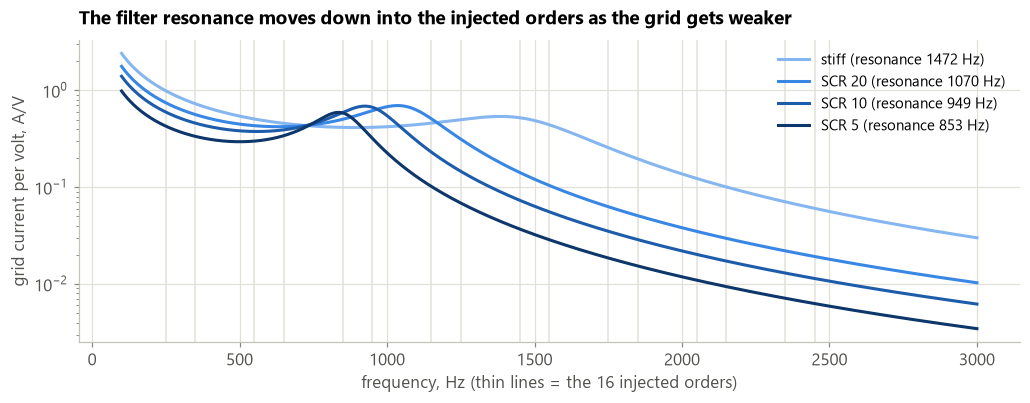

In [5]:
f = np.linspace(100, 3000, 3000)
fig, ax = A.panels(1, h=3.8)
rows = []
for g in A.GRIDS:
    ax[0].semilogy(f, A.lcl_response(f, g), color=A.GRID_COLOR[g], label="%s (resonance %.0f Hz)" % (g, A.lcl_resonance_hz(g)))
    rows.append({"grid": g, "resonance_Hz": A.lcl_resonance_hz(g), "resonance_order": A.lcl_resonance_hz(g) / 50})
for hh in P.ORDERS:
    if hh * 50 <= 3000:
        ax[0].axvline(hh * 50, color="#e1e0d9", lw=1, zorder=0)
ax[0].set_xlabel("frequency, Hz (thin lines = the 16 injected orders)"); ax[0].set_ylabel("grid current per volt, A/V")
ax[0].set_title("The filter resonance moves down into the injected orders as the grid gets weaker")
ax[0].legend(loc="upper right")
rr = pd.DataFrame(rows)
A.save(fig, "01_lcl_resonance", rr)
display(Markdown(A.md_table(rr, ".4g")))
claim("C1.4", "Grid inductance moves the LCL resonance from %.0f Hz (stiff) down to" % rr.resonance_Hz[0],
      "%.0f Hz (SCR 20) ... %.0f Hz (SCR 5), orders %.0f-%.0f" % (rr.resonance_Hz[1], rr.resonance_Hz[3], rr.resonance_order[3], rr.resonance_order[1]),
      "computed from hil_bench/params.py")

**Reading.** On a stiff grid the peak is at about 1470 Hz, above most of the injected orders. On SCR 20
to SCR 5 it sits at about 1070-850 Hz, which is the 17th-21st order. That is why the controller design
matters so much (notebook 04).

## The controller, in plain words

- **One resonant term per order** (proportional-resonant, PR). Each term
  has very high gain at exactly its own frequency, so the current at that order follows the request with
  almost no steady error. Discretised with prewarped Tustin.
- **Active damping**: the filter-capacitor current is fed back (gain 2 Ω) to damp the filter
  resonance.
- **One fixed tuning for every grid**: each resonant term's phase is set to the middle of the range it
  sees between a stiff grid and SCR 4, so it never needs to know the grid (notebook 04).
- **PLL** with a moving-average filter on its error, so the distorted PCC voltage does not
  shake the frequency estimate.
- **Frequency-adaptive resonators**: every term is retuned each sample to h × measured frequency (notebook 05).
- **Feed-forward of the fundamental voltage only**, so the PCC harmonics do not leak back into the inverter.

The C code is generated by `hil_bench/controller_c.py`; the design is in `hil_bench/pr_design.py`.

In [6]:
c = pd.DataFrame(claims)
c.to_csv(os.path.join(A.FIG, "claims_%s.csv" % NBID), index=False)
display(Markdown(A.md_table(c)))

| ID | Claim | Number | Source |
|---|---|---|---|
| C1.1 | LCL filter resonance on a stiff grid | 1472 Hz | hil_bench/params.py |
| C1.2 | All 16 orders at their IEEE 1547 limit add up to a total distortion (TRD) of | 6.82 % (IEEE 1547 allows 5 %) | IEEE Std 1547-2018 Table 26; computed here |
| C1.3 | Largest uniform master scale that keeps TRD at 5 % | 0.733 | computed here |
| C1.4 | Grid inductance moves the LCL resonance from 1472 Hz (stiff) down to | 1070 Hz (SCR 20) ... 853 Hz (SCR 5), orders 17-21 | computed from hil_bench/params.py |